# Task 04 – Customer Segmentation (Multiclass Classification)

**Problem statement:** an automobile company wants to enter new markets with its existing products. Its sales team already
puts current customers into **4 segments (A, B, C, D)** and runs a different marketing plan for each one.
The goal is to predict the **segment of a new customer** from basic information, so the right plan is used from day one.

**Task type:** supervised **multiclass classification** – target `Segmentation` (A / B / C / D).

**Dataset:** [Kaggle – Customer Segmentation](https://www.kaggle.com/datasets/kaushiksuresh147/customer-segmentation) – `Train.csv` (8,068 customers) and `Test.csv` (2,627 customers).

| Column | Meaning |
|---|---|
| ID | customer id |
| Gender | Male / Female |
| Ever_Married | Yes / No |
| Age | age in years |
| Graduated | Yes / No |
| Profession | Artist, Healthcare, Entertainment, Engineer, Doctor, ... |
| Work_Experience | years of work experience |
| Spending_Score | Low / Average / High |
| Family_Size | number of family members |
| Var_1 | anonymised category (Cat_1 ... Cat_7) |
| **Segmentation** | **target** – A / B / C / D |

**Metrics:** Accuracy (main – the 4 classes are almost balanced), macro Precision / Recall / F1, ROC-AUC and Average Precision (one-vs-rest, macro average).

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also hide warnings inside the parallel workers (n_jobs=-1)
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('dataset/Train.csv')
test_file = pd.read_csv('dataset/Test.csv')
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [3]:
df.shape, test_file.shape

((8068, 11), (2627, 11))

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   object 
 2   Ever_Married     7928 non-null   object 
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   object 
 5   Profession       7944 non-null   object 
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   object 
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   object 
 10  Segmentation     8068 non-null   object 
dtypes: float64(2), int64(2), object(7)
memory usage: 693.5+ KB


In [5]:
df.describe()

,ID,Age,Work_Experience,Family_Size
count,8068.000000,8068.000000,7239.000000,7733.000000
mean,463479.214551,43.466906,2.641663,2.850123
std,2595.381232,16.711696,3.406763,1.531413
min,458982.000000,18.000000,0.000000,1.000000
25%,461240.750000,30.000000,0.000000,2.000000
50%,463472.500000,40.000000,1.000000,3.000000
75%,465744.250000,53.000000,4.000000,4.000000
max,467974.000000,89.000000,14.000000,9.000000


# Data Understanding

In [6]:
print((df['Segmentation'].value_counts(normalize=True).sort_index() * 100).round(1))
for col in ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']:
    print(df[col].value_counts().to_dict())

Segmentation
A    24.4
B    23.0
C    24.4
D    28.1
Name: proportion, dtype: float64
{'Male': 4417, 'Female': 3651}
{'Yes': 4643, 'No': 3285}
{'Yes': 4968, 'No': 3022}
{'Artist': 2516, 'Healthcare': 1332, 'Entertainment': 949, 'Engineer': 699, 'Doctor': 688, 'Lawyer': 623, 'Executive': 599, 'Marketing': 292, 'Homemaker': 246}
{'Low': 4878, 'Average': 1974, 'High': 1216}
{'Cat_6': 5238, 'Cat_4': 1089, 'Cat_3': 822, 'Cat_2': 422, 'Cat_7': 203, 'Cat_1': 133, 'Cat_5': 85}


The 4 segments are **almost balanced** (23 % – 28 % each) → **accuracy** is a fair main metric (random guessing ≈ 25 %).

## Can `Test.csv` be used as the test set?

In [7]:
same_ids = set(df['ID']) & set(test_file['ID'])
print('Test.csv customers whose ID is also in Train.csv:', len(same_ids), 'of', len(test_file))

both = test_file.merge(df, on='ID', suffixes=('_test', '_train'))
print('Same Age in both files  :', round((both['Age_test'] == both['Age_train']).mean() * 100, 1), '%')
print('Same segment in both    :', round((both['Segmentation_test'] == both['Segmentation_train']).mean() * 100, 1), '%')
print('\nSegments in Test.csv:\n', (test_file['Segmentation'].value_counts(normalize=True).sort_index() * 100).round(1))

Test.csv customers whose ID is also in Train.csv: 2332 of 2627
Same Age in both files  : 11.7 %
Same segment in both    : 30.3 %

Segments in Test.csv:
 Segmentation
A    32.2
B    20.9
C    18.0
D    28.9
Name: proportion, dtype: float64


- 2,332 of the 2,627 `Test.csv` IDs also exist in `Train.csv`, but they are **different people** (different age, and the segment matches only ~30 % – close to random).
- At the end of the notebook we check `Test.csv` with the final model: it gives only ~34 % accuracy, much lower than cross-validation, so its labels do not follow the same pattern as `Train.csv`
  (this is a known problem of this Kaggle dataset).
- So the **official test set is an 80 / 20 stratified split of `Train.csv`**, and `Test.csv` is only reported as a side note.

# Data Cleaning

In [8]:
df.drop('ID', axis=1, inplace=True)   # just an id, no information
df.isnull().sum()

Gender               0
Ever_Married       140
Age                  0
Graduated           78
Profession         124
Work_Experience    829
Spending_Score       0
Family_Size        335
Var_1               76
Segmentation         0
dtype: int64

Missing values (Work_Experience 10 %, Family_Size 4 %, and a few in Ever_Married / Graduated / Profession / Var_1) are filled **inside the Pipeline**
(median for numbers, most frequent value for categories), using the training data only.

In [9]:
print('Number of duplicate rows : ', df.duplicated().sum())

Number of duplicate rows :  417


After dropping `ID`, 417 rows look the same as another row. They are **different customers** (different IDs) who happen to have the same profile
(e.g. same age, profession and family size), so they are **kept** – removing them would remove real customers.

# EDA & Statistical Analysis

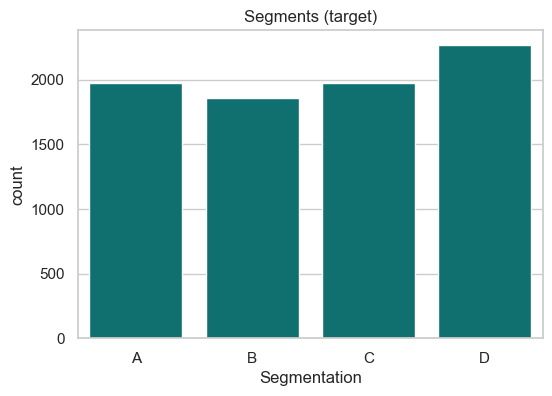

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Segmentation', data=df, order=['A', 'B', 'C', 'D'], color='teal')
plt.title('Segments (target)')
plt.show()

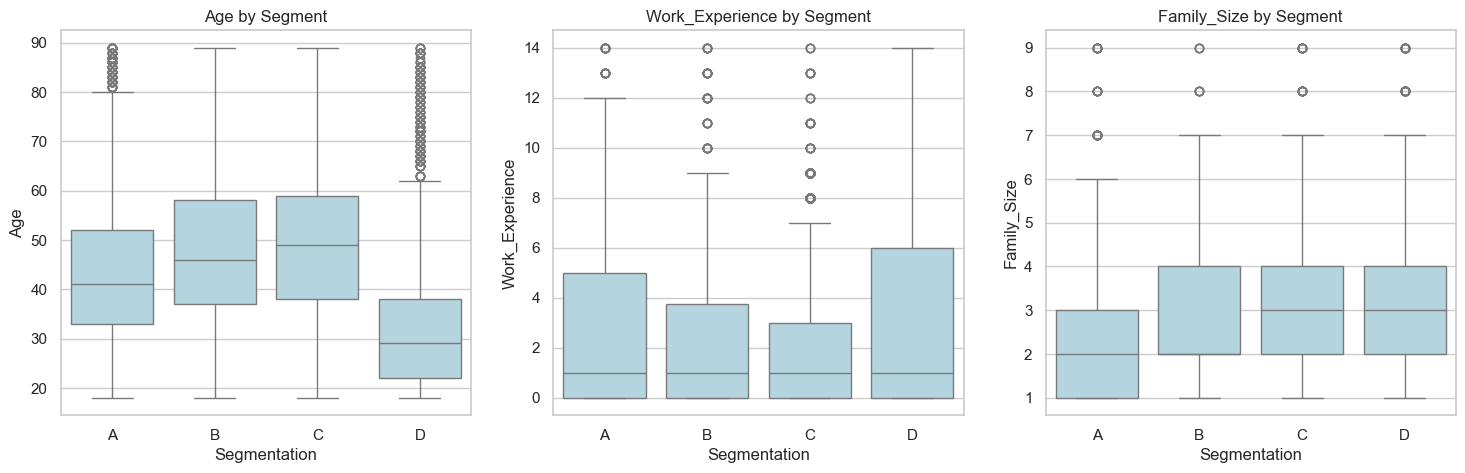

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['Age', 'Work_Experience', 'Family_Size']):
    sns.boxplot(x='Segmentation', y=col, data=df, order=['A', 'B', 'C', 'D'], color='lightblue', ax=ax[i])
    ax[i].set_title(col + ' by Segment')
plt.show()

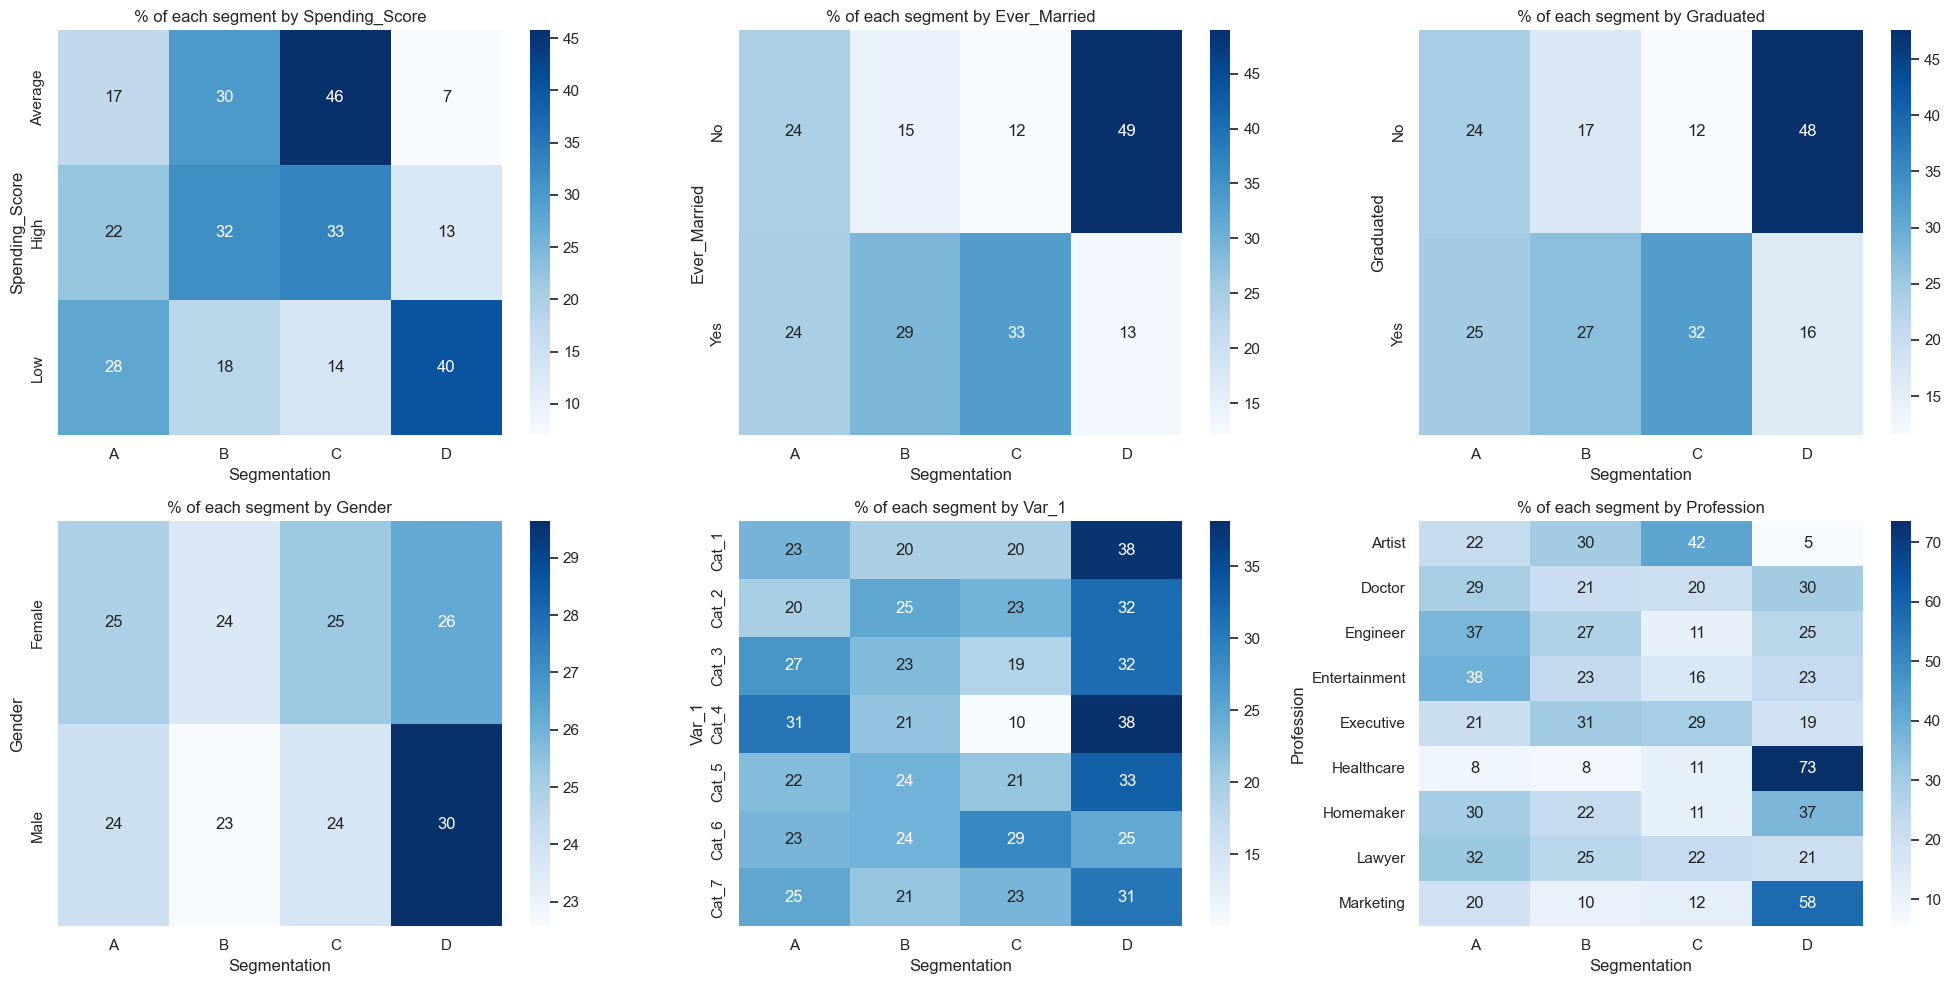

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
ax = ax.flatten()
for i, col in enumerate(['Spending_Score', 'Ever_Married', 'Graduated', 'Gender', 'Var_1', 'Profession']):
    table = pd.crosstab(df[col], df['Segmentation'], normalize='index') * 100
    sns.heatmap(table, annot=True, fmt='.0f', cmap='Blues', ax=ax[i])
    ax[i].set_title('% of each segment by ' + col)
plt.tight_layout()
plt.show()

In [13]:
from scipy.stats import chi2_contingency, f_oneway

print('Chi-square test (categories vs segment):')
for col in ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']:
    print(f'  {col:16s} p-value = {chi2_contingency(pd.crosstab(df[col], df["Segmentation"]))[1]:.4g}')

print('\nANOVA (numbers vs segment):')
for col in ['Age', 'Work_Experience', 'Family_Size']:
    groups = [g[col].dropna() for _, g in df.groupby('Segmentation')]
    print(f'  {col:16s} p-value = {f_oneway(*groups).pvalue:.4g}')

Chi-square test (categories vs segment):
  Gender           p-value = 0.009618
  Ever_Married     p-value = 1.763e-305
  Graduated        p-value = 4.385e-231
  Profession       p-value = 0
  Spending_Score   p-value = 0
  Var_1            p-value = 1.646e-41

ANOVA (numbers vs segment):
  Age              p-value = 2.189e-285
  Work_Experience  p-value = 9.62e-15
  Family_Size      p-value = 1.716e-65


**EDA findings**
- **Segment D is very different:** young (median age 29), mostly **not married** (27 %), **not graduated** (36 %), **low spending** (87 %), and **73 % of Healthcare workers** are in D.
- **Segment C:** the oldest (median 49), most married (79 %) and graduated (82 %), and the highest share of average / high spending; artists are mostly C (42 %).
- **Segments A and B** are in the middle (median age 41 and 46) and look **similar** to each other → we expect the model to confuse them.
- **Statistical tests:** every feature is significant (chi-square / ANOVA p < 0.05); the strongest are Profession, Spending_Score, Age, Ever_Married and Graduated. Gender is the weakest (p ≈ 0.01).

# Outliers

In [14]:
for col in ['Age', 'Work_Experience', 'Family_Size']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(f'{col:16s} outliers = {outliers.sum():4d}   range = {df[col].min()} to {df[col].max()}')

Age              outliers =   71   range = 18 to 89
Work_Experience  outliers =  189   range = 0.0 to 14.0
Family_Size      outliers =   94   range = 1.0 to 9.0


The IQR rule flags some long work experience (≥ 11 years) and large families (≥ 8), but these are **real, possible values** (not errors),
and they help separate the segments, so they are **kept**. Scaling and tree models handle them.

# Feature Engineering / Encoding choices

- `Spending_Score` has a **natural order** (Low < Average < High) → **OrdinalEncoder** (0, 1, 2), so the model knows High > Average > Low.
- The other categories have no order → **OneHotEncoder**.
- No new columns are needed: the EDA shows that age, marriage, graduation, profession and spending already separate the segments well,
  and the tree / boosting models can learn the combinations by themselves.

# Feature Selection

All features have a **significant** relation with the segment (chi-square / ANOVA p-values < 0.05, even Gender p ≈ 0.01) → **all are kept**.

In [15]:
num_cols = ['Age', 'Work_Experience', 'Family_Size']
ord_cols = ['Spending_Score']
cat_cols = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Var_1']

# Split data

In [16]:
from sklearn.model_selection import train_test_split

segments = ['A', 'B', 'C', 'D']
X = df[num_cols + ord_cols + cat_cols]
y = df['Segmentation'].map({'A': 0, 'B': 1, 'C': 2, 'D': 3})   # numbers 0-3 (needed by XGBoost)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (6454, 9)  y_train =  (6454,)
X_test  =  (1614, 9)  y_test  =  (1614,)


# Preprocessing (Pipeline + ColumnTransformer)

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['Low', 'Average', 'High']]))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('ord', ord_pipeline, ord_cols),
    ('cat', cat_pipeline, cat_cols)
])

Everything is inside a **Pipeline** → the imputers, scaler and encoders learn from the training folds only → **no data leakage**.

# Models

| Model | Why it is tried |
|---|---|
| Logistic Regression | simple, explainable baseline (multinomial for 4 classes) |
| KNN | similar customers belong to the same segment |
| Decision Tree | easy-to-read rules, but overfits |
| Random Forest / Extra Trees | many trees averaged → less overfitting |
| SVM | separating boundaries between the segments (RBF kernel) |
| Naive Bayes | very fast probabilistic baseline |
| Gradient Boosting / AdaBoost | each tree fixes the mistakes of the previous ones |
| XGBoost / LightGBM | fast, regularized boosting – usually strong on tabular data |

Regression models are **excluded** because the target is a class, not a number.

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.preprocessing import label_binarize

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [19]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(algorithm='SAMME', random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
}

## Model comparison with 5-fold stratified cross-validation (training data only)

In [20]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'Accuracy': 'accuracy', 'F1 (macro)': 'f1_macro', 'Precision (macro)': 'precision_macro',
           'Recall (macro)': 'recall_macro', 'ROC-AUC (ovr)': 'roc_auc_ovr'}

results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {'Train Accuracy': cv['train_Accuracy'].mean()}
    results[name].update({metric: cv['test_' + metric].mean() for metric in scoring})
    print(f"{name:20s} CV Accuracy = {results[name]['Accuracy']:.4f}")

Logistic Regression  CV Accuracy = 0.5031


KNN                  CV Accuracy = 0.4580


Decision Tree        CV Accuracy = 0.4393


Random Forest        CV Accuracy = 0.4764


SVM                  CV Accuracy = 0.5246
Naive Bayes          CV Accuracy = 0.4634


Gradient Boosting    CV Accuracy = 0.5310


AdaBoost             CV Accuracy = 0.4954


Extra Trees          CV Accuracy = 0.4549


XGBoost              CV Accuracy = 0.5034


LightGBM             CV Accuracy = 0.5198


In [21]:
comparison = pd.DataFrame(results).T.sort_values('Accuracy', ascending=False)
comparison.round(4)

,Train Accuracy,Accuracy,F1 (macro),Precision (macro),Recall (macro),ROC-AUC (ovr)
Gradient Boosting,0.5933,0.5310,0.5166,0.5160,0.5209,0.7809
SVM,0.5786,0.5246,0.5095,0.5114,0.5144,0.7740
LightGBM,0.7244,0.5198,0.5055,0.5049,0.5100,0.7722
XGBoost,0.8021,0.5034,0.4921,0.4917,0.4949,0.7619
Logistic Regression,0.5083,0.5031,0.4739,0.4817,0.4913,0.7513
AdaBoost,0.4995,0.4954,0.4811,0.4819,0.4854,0.7480
Random Forest,0.9625,0.4764,0.4652,0.4647,0.4676,0.7356
Naive Bayes,0.4711,0.4634,0.4279,0.4435,0.4525,0.7193
KNN,0.6228,0.4580,0.4536,0.4598,0.4515,0.7066
Extra Trees,0.9625,0.4549,0.4466,0.4475,0.4473,0.7038


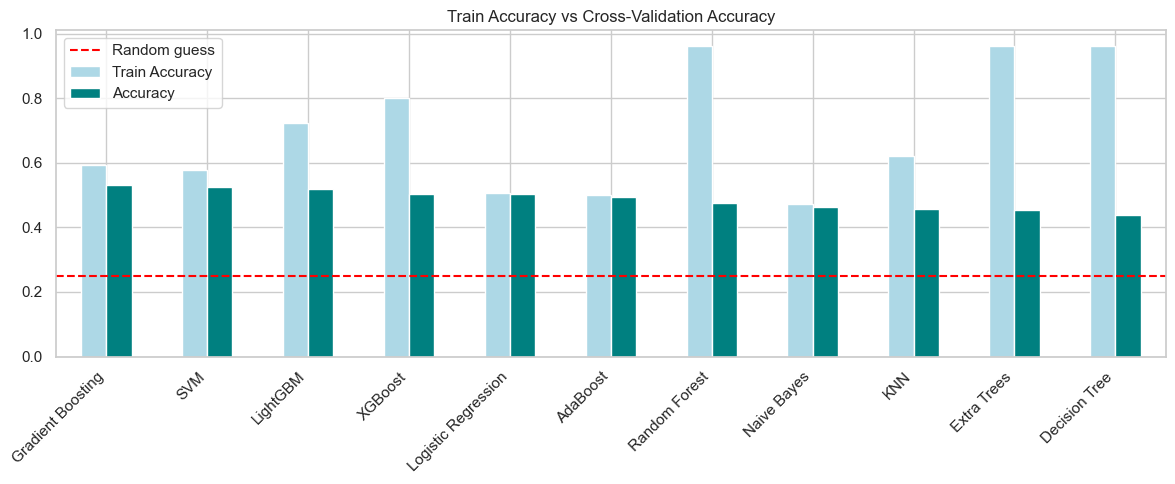

In [22]:
comparison[['Train Accuracy', 'Accuracy']].plot(kind='bar', figsize=(12, 5), color=['lightblue', 'teal'])
plt.axhline(0.25, color='red', linestyle='--', label='Random guess')
plt.title('Train Accuracy vs Cross-Validation Accuracy')
plt.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparison results (5-fold stratified CV on the training data)**
- **Best:** Gradient Boosting (CV accuracy 0.531), SVM (0.525), LightGBM (0.520) – about **twice better than random guessing (0.25)**.
- **Logistic Regression** (0.503) is close behind: the segments are not separated by straight lines only.
- **Overfitting:** Decision Tree, Random Forest and Extra Trees reach **0.96 on training** but only 0.44 – 0.48 in CV – they memorize individual customers
  (many customers share the same profile but different segments). XGBoost also overfits (0.80 → 0.50).
- **Naive Bayes** (0.46) and **KNN** (0.46) are the weakest.
- The macro F1 and ROC-AUC rank the models in almost the same order as accuracy (best ROC-AUC 0.78 for Gradient Boosting).
- The **top 3 (Gradient Boosting, SVM, LightGBM)** are tuned.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models by CV accuracy** are tuned with 5-fold stratified cross-validation on the training data.

In [23]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01, 0.1, 1, 10]},
    'KNN': {'model__n_neighbors': [15, 31, 51], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [4, 6, 8], 'model__min_samples_leaf': [10, 30, 50]},
    'Random Forest': {'model__n_estimators': [200, 400], 'model__max_depth': [6, 10, None], 'model__min_samples_leaf': [1, 5]},
    'SVM': {'model__C': [0.3, 1, 3], 'model__gamma': ['scale', 0.05]},
    'Naive Bayes': {'model__var_smoothing': [1e-9, 1e-7, 1e-5]},
    'Gradient Boosting': {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]},
    'AdaBoost': {'model__n_estimators': [50, 200], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [200, 400], 'model__max_depth': [6, 10, None], 'model__min_samples_leaf': [1, 5]},
    'XGBoost': {'model__n_estimators': [100, 300], 'model__max_depth': [2, 4], 'model__learning_rate': [0.05, 0.1]},
    'LightGBM': {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 15], 'model__learning_rate': [0.03, 0.1]},
}

In [24]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=kfold, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 4), '(CV accuracy)')

Gradient Boosting
Parameter grid : {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]}
best_params_   : {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
best_score_    : 0.531 (CV accuracy)


SVM
Parameter grid : {'model__C': [0.3, 1, 3], 'model__gamma': ['scale', 0.05]}
best_params_   : {'model__C': 1, 'model__gamma': 'scale'}
best_score_    : 0.5246 (CV accuracy)


LightGBM
Parameter grid : {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 15], 'model__learning_rate': [0.03, 0.1]}
best_params_   : {'model__learning_rate': 0.03, 'model__n_estimators': 100, 'model__num_leaves': 15}
best_score_    : 0.5356 (CV accuracy)


## Before vs after tuning (cross-validation accuracy)

In [25]:
tuning = pd.DataFrame({
    'CV Accuracy before tuning': comparison.loc[top_models, 'Accuracy'],
    'CV Accuracy after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV Accuracy after tuning'] - tuning['CV Accuracy before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV Accuracy after tuning', ascending=False)
tuning

,CV Accuracy before tuning,CV Accuracy after tuning,Improvement,Best params
LightGBM,0.519833,0.535636,0.015804,"{'model__learning_rate': 0.03, 'model__n_estim..."
Gradient Boosting,0.530989,0.530989,0.000000,"{'model__learning_rate': 0.1, 'model__max_dept..."
SVM,0.524636,0.524636,0.000000,"{'model__C': 1, 'model__gamma': 'scale'}"


In [26]:
best_name = tuning.index[0]   # chosen by the cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : LightGBM
Best params: {'model__learning_rate': 0.03, 'model__n_estimators': 100, 'model__num_leaves': 15}


# Final Evaluation on the Test Set

For 4 classes, precision / recall / F1 are calculated **per class** and then **macro-averaged** (simple mean of the 4 classes, every segment counts the same).
ROC-AUC and Average Precision use **one-vs-rest**: each segment against all the others, then macro-averaged.

In [27]:
def classification_metrics(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision (macro)': precision_score(y, y_pred, average='macro'),
        'Recall (macro)': recall_score(y, y_pred, average='macro'),
        'F1 (macro)': f1_score(y, y_pred, average='macro'),
        'ROC-AUC (ovr, macro)': roc_auc_score(y, y_prob, multi_class='ovr', average='macro'),
        'AP (macro)': average_precision_score(label_binarize(y, classes=[0, 1, 2, 3]), y_prob, average='macro'),
    }

base_model = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]).fit(X_train, y_train)   # before tuning

final = pd.DataFrame({
    'Before tuning': classification_metrics(base_model, X_test, y_test),
    'After tuning': classification_metrics(best_model, X_test, y_test),
}).T
final.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),"ROC-AUC (ovr, macro)",AP (macro)
Before tuning,0.5366,0.5205,0.5258,0.5211,0.7880,0.5563
After tuning,0.5440,0.5256,0.5318,0.5241,0.7972,0.5687


In [28]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)

print(classification_report(y_test, y_pred, target_names=segments))

              precision    recall  f1-score   support

           A       0.46      0.42      0.44       394
           B       0.45      0.33      0.38       372
           C       0.57      0.59      0.58       394
           D       0.63      0.79      0.70       454

    accuracy                           0.54      1614
   macro avg       0.53      0.53      0.52      1614
weighted avg       0.53      0.54      0.53      1614



## Confusion Matrix

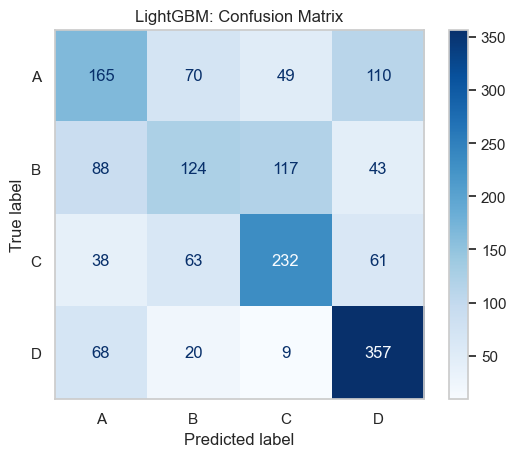

In [29]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=segments, cmap='Blues')
plt.title(best_name + ': Confusion Matrix')
plt.grid(False)
plt.show()

## ROC & Precision-Recall curves (one-vs-rest)

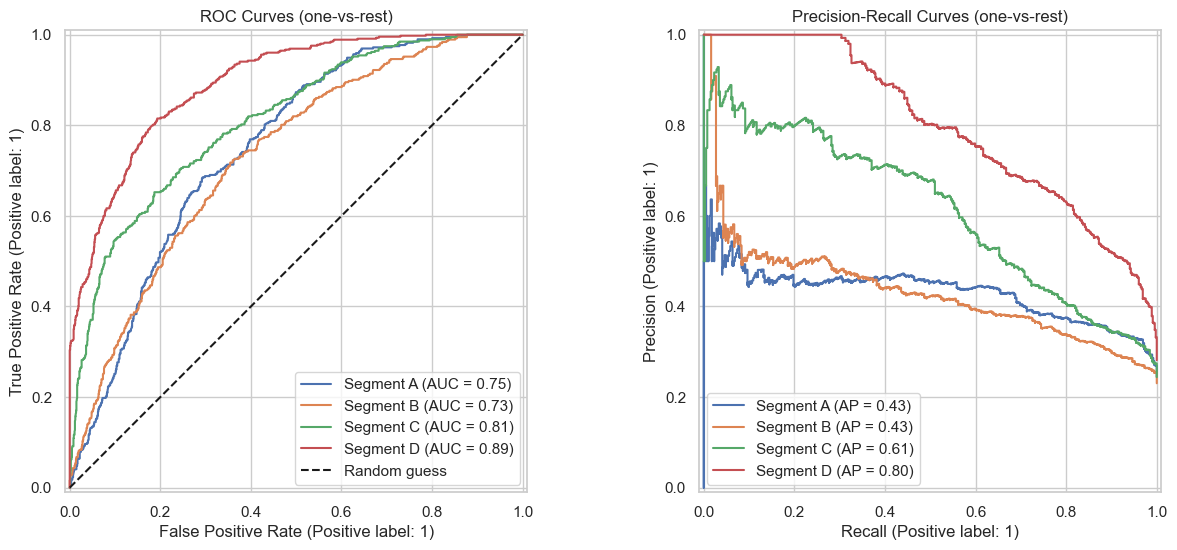

Segment A:  ROC-AUC = 0.751   AP = 0.432
Segment B:  ROC-AUC = 0.733   AP = 0.433
Segment C:  ROC-AUC = 0.812   AP = 0.611
Segment D:  ROC-AUC = 0.894   AP = 0.798


In [30]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for i, seg in enumerate(segments):
    RocCurveDisplay.from_predictions(y_test_bin[:, i], y_prob[:, i], name='Segment ' + seg, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test_bin[:, i], y_prob[:, i], name='Segment ' + seg, ax=ax[1])
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
ax[0].set_title('ROC Curves (one-vs-rest)')
ax[0].legend()
ax[1].set_title('Precision-Recall Curves (one-vs-rest)')
plt.show()

for i, seg in enumerate(segments):
    print(f'Segment {seg}:  ROC-AUC = {roc_auc_score(y_test_bin[:, i], y_prob[:, i]):.3f}   AP = {average_precision_score(y_test_bin[:, i], y_prob[:, i]):.3f}')

## Which features matter? (permutation importance on the test set)

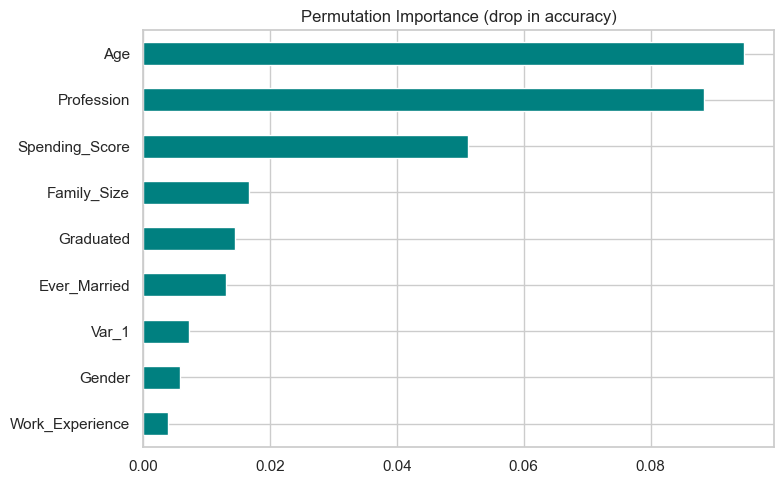

In [31]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in accuracy)')
plt.tight_layout()
plt.show()

## Side note: the model on `Test.csv`

In [32]:
y_file = test_file['Segmentation'].map({'A': 0, 'B': 1, 'C': 2, 'D': 3})
print('Accuracy on Test.csv:', round(accuracy_score(y_file, best_model.predict(test_file[X.columns])), 4))

Accuracy on Test.csv: 0.3403


**Interpretation of results**
- **GridSearchCV:** LightGBM improved the most (0.520 → **0.536**, with a smaller learning rate 0.03 and 100 trees – i.e. **less overfitting**) and became the best model.
  For Gradient Boosting and SVM the default parameters were already the best in their grids (no change).
- **Test set (LightGBM):** accuracy **0.544**, macro F1 0.524, ROC-AUC (one-vs-rest, macro) **0.797**, macro AP 0.569. Tuning also helped on the test set (accuracy 0.537 → 0.544, AUC 0.788 → 0.797),
  and the test accuracy is close to the CV accuracy (0.536) → no overfitting.
- **Per segment:** **D is the easiest** (recall 0.79, F1 0.70, AUC 0.89) – young, unmarried, low-spending customers are easy to spot. **C** is fairly good (F1 0.58, AUC 0.81).
  **A and B are the hardest** (F1 0.44 and 0.38, AUC ≈ 0.75): the confusion matrix shows B is often predicted as C (117) or A (88), and A is often predicted as D (110).
- **ROC / PR curves (one-vs-rest):** every curve is clearly above random; D and C have the highest curves, A and B the lowest – the same story as the confusion matrix.
- **Averaging:** macro averaging gives every segment the same weight, so the weak A / B results are not hidden by the strong D results.
- **Most important features:** **Age**, **Profession** and **Spending_Score**, then Family_Size, Graduated and Ever_Married; Work_Experience and Gender matter least.
- **Test.csv:** the model gets only **34 %** on `Test.csv` (almost random), confirming that its labels do not follow the same pattern as `Train.csv` – this is why it was not used as the test set.

# Gradio App (deployment)
The final model is put into a small web app. The user enters the customer's information and the app shows the **predicted segment**
together with the **probability of all 4 segments**.

- The tuned pipeline (`best_model`) is used directly, so the app gives exactly the same answers as the evaluation above.
- Showing all 4 probabilities follows the recommendation: for customers predicted as **A or B**, check the top-2 segments before choosing the marketing plan.
- Run the cell below to open the app **inside the notebook** (or at the local link it prints).

In [33]:
import gradio as gr

def predict_segment(gender, ever_married, age, graduated, profession, work_experience, spending_score, family_size, var_1):
    customer = pd.DataFrame([{
        'Age': age, 'Work_Experience': work_experience, 'Family_Size': family_size, 'Spending_Score': spending_score,
        'Gender': gender, 'Ever_Married': ever_married, 'Graduated': graduated, 'Profession': profession, 'Var_1': var_1,
    }])
    probs = best_model.predict_proba(customer[X.columns])[0]
    best = segments[probs.argmax()]
    return 'Segment ' + best, {'Segment ' + s: float(p) for s, p in zip(segments, probs)}

demo = gr.Interface(
    fn=predict_segment,
    inputs=[
        gr.Radio(['Male', 'Female'], value='Male', label='Gender'),
        gr.Radio(['Yes', 'No'], value='Yes', label='Ever Married'),
        gr.Slider(18, 89, value=40, step=1, label='Age'),
        gr.Radio(['Yes', 'No'], value='Yes', label='Graduated'),
        gr.Dropdown(sorted(X_train['Profession'].dropna().unique()), value='Artist', label='Profession'),
        gr.Number(value=1, label='Work Experience (years)', precision=0),
        gr.Radio(['Low', 'Average', 'High'], value='Low', label='Spending Score'),
        gr.Number(value=3, label='Family Size', precision=0),
        gr.Dropdown(sorted(X_train['Var_1'].dropna().unique()), value='Cat_6', label='Var_1'),
    ],
    outputs=[
        gr.Textbox(label='Predicted segment'),
        gr.Label(num_top_classes=4, label='Probability of each segment'),
    ],
    examples=[
        ['Male', 'No', 22, 'No', 'Healthcare', 1, 'Low', 4, 'Cat_4'],
        ['Female', 'Yes', 45, 'Yes', 'Artist', 0, 'Average', 2, 'Cat_6'],
        ['Male', 'Yes', 67, 'Yes', 'Lawyer', 0, 'High', 2, 'Cat_6'],
    ],
    title='Customer Segmentation',
    description='Enter the customer information to get the predicted marketing segment (A, B, C or D).',
)

demo.launch()

Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.


In [34]:
# quick check: the app function gives the same answers as the model
for c in [['Male', 'No', 22, 'No', 'Healthcare', 1, 'Low', 4, 'Cat_4'],
          ['Female', 'Yes', 45, 'Yes', 'Artist', 0, 'Average', 2, 'Cat_6'],
          ['Male', 'Yes', 67, 'Yes', 'Lawyer', 0, 'High', 2, 'Cat_6']]:
    label, probs = predict_segment(*c)
    print(f'{c[0]:6s} age {c[2]}  {c[4]:10s} spending {c[6]:7s} ->  {label}  ({probs[label]:.0%})')

Male   age 22  Healthcare spending Low     ->  Segment D  (97%)
Female age 45  Artist     spending Average ->  Segment C  (60%)
Male   age 67  Lawyer     spending High    ->  Segment C  (45%)


# Conclusions & Recommendations

**Conclusions**
1. The 4 segments are almost balanced, so accuracy and **macro-averaged** precision / recall / F1, ROC-AUC and AP (one-vs-rest) were used.
2. Segments are explained mainly by **age, profession and spending score**; segment D (young, single, low spending) is very clear, while A and B overlap a lot.
3. 11 classification models were compared with stratified 5-fold CV; tree ensembles overfit badly, while boosting and SVM generalize best.
4. The final **LightGBM (tuned)** reaches **54 % accuracy and ROC-AUC 0.80** on the test split – more than twice better than random guessing (25 %).
5. `Test.csv` was **not** used as the test set because its labels don't match the patterns in `Train.csv` (≈ 34 % accuracy for every model, and different people under the same IDs).

**Recommendations**
- Use the model for the clear segments (D and C) with confidence; for customers predicted as A or B, check the top-2 probabilities before choosing the marketing plan.
- The features are too basic to separate A and B – collect **income, car ownership, purchase history and location** to improve the segmentation.
- Ask the data owner to fix or explain the labels of `Test.csv` before using it for evaluation.